# TC Seed Convective Orgnanization Metrics Notebook


============================================================================================

## TC Seed Convective Organization Metrics Analysis 

This POD calculates convective organization metrics for developing and non-developing tropical cyclone seed disturbances. These metrics include a simple fractional area of rainfall rates at and above the 95th Percentile and complex clustering metrics such as $L_{org}$, $I_{org}$, and $SCAI$. Snapshots are taken along the track of each developing and non-developing track, then each snapshot is composited by a function of its maximum wind speed (Vmax), and then metrics are calculated for each snapshot and then averaged within each wind intensity bin (6-9 m/s, 9-12 m/s, and 12-15 m/s). We compare results from  "observational data" ERA5 and a climate model simulation.

## Version & Contact Info

- Version Information: Version 1 (11/05/2026)
- PI: Allison Wing, Florida State University, awing@fsu.edu
- Developer: Jacob Hamil, Florida State University, jeh25d@fsu.edu
- Other Contributors: Grace Muesing, Suzana Camargo, Daehyun Kim, and Jihong Moon

## Open source copyright agreement 

The MDTF framework is distributed under the LGPLv3 license (see LICENSE.txt)

## Functionality

Pre-calculated TC seed track data, in which the developing seeds are already matched to TC tracks, is required as an input to the POD as obs data (a NetCDF file). The code splits the tracks into Northern and Southern Hemisphere and into developing/non-developing, and then for each snapshot along the track extracts convective and large-scale precipitation in 10x10 degree boxes centered around the tracked seed center. The two precipitation types are summed them together to form total precipitation. Southern Hemisphere snapshots are flipped to orient poleward in the positive-y direction relative to the seed center to match the Northern Hemisphere snapshots (so poleward is in the positive-y direction in both hemispheres). We disregard any seed snapshot that has a central latitude greater than 30 degrees. 

Convective organization metrics are then computed for each snapshot. 

Next we composite the developing and non-developing seed snapshots and calculated organization metrics as a function of their maximum wind intensity using 3 separate bins at low intensities pre-TC genesis: 6-9 m/s, 9-12 m/s, and 12-15 m/s. From there, we load in our pre-digested "observational" ERA5 data which has already been composited. 

After the compositing step, we plot spatial 10 x 10-degree maps of the average precipitation rate for each intensity bin and outline the 95th percentile rainfall rate for both the model and ERA5. We also plot the average convective organization metrics for each bin to make comparisons between developing and non-developing seeds in both the model and the observation.

Python Files called:

1. **Plotting_File.py** Creates the observation precipitation rate as function of Vmax spatial map for Observation and Model
2. **Convective_Org.py** Calculates $L_{org}$ and $I_{org}$ convective organization metrics


## Required Programming Language and Libraries

- Python 3.11.7
- numpy, matplotlib, xarray, pandas, cftime, itertools, scipy, skimage, glob


## Required Model Output Variables 

3-D (time-lat-lon): 6-hourly instantaneous: `PRECC`, `PRECL`

In addition to model output, this POD requires pre-computed TC seed track data, provided as observational/ancillary data (OBS_DATA), plus the ERA5 reanalysis composite dataset used for comparison in the plots. 


## References

1. Moon, J., Kim, D., Wing, A. A., Camargo, S. J., Emlaw, G. N., Starr, J. C., & Cha, D.‐H. (2025). Tropical Cyclone Seed Disturbances in ERA5. Journal of Climate, 38(18), 4625–4639. https://doi.org/10.1175/JCLI‐D‐24‐0291.1
2. Tobin I, Bony S, Roca R. 2012. Observational Evidence for Relationships between the Degree of Aggregation of Deep Convection, Water Vapor, Surface Fluxes, and Radiation. Journal of Climate 25(20), doi:10.1175/jcli-d-11-00258.1, URL http://dx.doi.org/10.1175/JCLI-D-11-00258.1.
3. Biagioli G, Tompkins AM. 2023. Measuring Convective Organization. Journal of the Atmospheric Sciences 80(12), doi:10.1175/jas-d-23-0103.1, URL http://dx.doi.org/10.1175/JAS-D-23-0103.1.
4. Tompkins AM, Semie AG. 2017. Organization of tropical convection in low vertical wind shears: Role of updraft entrainment. Journal of Advances in Modeling Earth Systems 9(2), doi:10.1002/2016ms000802, URL http://dx.doi.org/10.1002/2016MS000802.


# Section 1: Settings

In [1]:
#Loading in Necessary Python Libraries 
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import cftime
from itertools import combinations
from scipy import ndimage
from scipy.ndimage import label, generate_binary_structure, center_of_mass

import glob as glob

import intake
import yaml

### Interactive vs. framework mode

The framework exports `case_env_file`, `POD_HOME`, `WORK_DIR`, `OBS_DATA` and the
per-case environment variables (`startdate`, `enddate`, `modelname`, `latres`,
`lonres`) before running this notebook. When developing/testing the notebook
standalone in Jupyter, `case_env_file` will not be set, so we fill in placeholder
values below. **Edit the paths in the `if interactive:` block for local testing** --
they are ignored when the notebook is run by the framework.

In [2]:
# True when running standalone in Jupyter for development/testing;
# False when launched by the framework via nbconvert.
interactive = "case_env_file" not in os.environ

if interactive:
    # ------------------------------------------------------------------
    # STANDALONE / INTERACTIVE SETTINGS -- edit these paths for local testing.
    # ------------------------------------------------------------------
    os.environ["POD_HOME"] = os.path.abspath(".")
    os.environ.setdefault("WORK_DIR", "/home/awing/mdtf/wkdir/TCseed")     # <- edit for local testing
    os.environ.setdefault("OBS_DATA", "/huracan/tank4/cornell/GCM/mdtf/inputdata/obs_data/TCseed")  # <- edit for local testing
    os.environ.setdefault("case_env_file","/home/awing/mdtf/MDTF-diagnostics/catalogs/CESM-MDTFv3_catalog.csv")
    os.environ.setdefault("startdate", "2010")
    os.environ.setdefault("enddate", "2011")
    os.environ.setdefault("modelname", "CESM")
    os.environ.setdefault("latres", "0.942408376")
    os.environ.setdefault("lonres", "1.25")

print(f"Running in {'interactive/standalone' if interactive else 'framework'} mode")

Running in interactive/standalone mode


Note that TCseed is a single-case POD and the computation code below refers to the standard CESM dimension names. 

In [3]:
# Receive the catalog location from the framework (or set directly above for
# interactive testing, since a single-case POD case_env_file may just point at the
# catalog file itself rather than a case_info.yml).
case_env_file = os.environ["case_env_file"]
assert os.path.isfile(case_env_file), f"case environment file not found: {case_env_file}"

if case_env_file.endswith(".json") or case_env_file.endswith(".csv"):
    # interactive shortcut: case_env_file was set directly to the catalog file
    cat_def_file = case_env_file
else:
    with open(case_env_file, 'r') as stream:
        try:
            case_info = yaml.safe_load(stream)
        except yaml.YAMLError as exc:
            print(exc)
    cat_def_file = case_info['CATALOG_FILE']

In [4]:
# Analysis period and model grid settings 
start_year = int(os.environ["startdate"])
end_year = int(os.environ["enddate"])
modelname = str(os.environ["modelname"])
latres = float(os.environ["latres"])
lonres = float(os.environ["lonres"])

POD_HOME = os.environ["POD_HOME"]
WORK_DIR = os.environ["WORK_DIR"]
OBS_DATA = os.environ["OBS_DATA"]
os.makedirs(os.path.join(WORK_DIR, "model"), exist_ok=True)

# The 2 model variables TCseed needs, all instantaneous at 6-hourly frequency (see settings.jsonc)
varlist = ["PRECC", "PRECL"]

print(f"model: {modelname}, years: {start_year}-{end_year}, grid: {latres} x {lonres} deg")

model: CESM, years: 2010-2011, grid: 0.942408376 x 1.25 deg


# Section 2: Load data

 ### First, the data catalog

In [5]:
#Loading In Data Catalog and Looking at what's inside

catalog = pd.read_csv('/home/awing/mdtf/MDTF-diagnostics/catalogs/CESM-MDTFv3_catalog.csv')

catalog

,activity_id,assoc_files,institution_id,member_id,realm,variable_id,table_id,source_id,source_type,cell_methods,...,variant_label,grid_label,units,time_range,chunk_freq,standard_name,long_name,frequency,file_name,path
0,CESM,NaN,NCAR,NaN,atmos,FLNS,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,net_longwave_flux_at_surface,Net longwave flux at surface,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
1,CESM,NaN,NCAR,NaN,atmos,FLNSC,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,clearsky_net_longwave_flux_at_surface,Clearsky net longwave flux at surface,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
2,CESM,NaN,NCAR,NaN,atmos,FLUT,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,toa_outgoing_longwave_flux,Upwelling longwave flux at top of model,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
3,CESM,NaN,NCAR,NaN,atmos,FLUTC,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,clearsky_upwelling_longwave_flux_at_top_of_model,Clearsky upwelling longwave flux at top of model,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
4,CESM,NaN,NCAR,NaN,atmos,FSNS,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,net_solar_flux_at_surface,Net solar flux at surface,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
5,CESM,NaN,NCAR,NaN,atmos,FSNSC,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,clearsky_net_solar_flux_at_surface,Clearsky net solar flux at surface,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
6,CESM,NaN,NCAR,NaN,atmos,FSNTOA,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,net_solar_flux_at_top_of_atmosphere,Net solar flux at top of atmosphere,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
7,CESM,NaN,NCAR,NaN,atmos,FSNTOAC,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,clearsky_net_solar_flux_at_top_of_atmosphere,Clearsky net solar flux at top of atmosphere,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
8,CESM,NaN,NCAR,NaN,atmos,LHFLX,NaN,NaN,NaN,time: mean,...,NaN,NaN,W m-2,20130101:010000-20150101:000000,NaN,surface_upward_latent_heat_flux,Surface latent heat flux,1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...
9,CESM,NaN,NCAR,NaN,atmos,PRECC,NaN,NaN,NaN,time: mean,...,NaN,NaN,m s-1,20130101:010000-20150101:000000,NaN,convective_precipitation_rate,Convective precipitation rate (liq + ice),1hr,NaN,/huracan/tank4/cornell/GCM/CESM-MDTFv3/1hr/ces...


Find necessary variables in the catalog

In [6]:
#Now we can start the process of Getting Precip Files in Order

convective_Precip = xr.open_dataset(catalog['path'][22])
Large_Scale_Precip = xr.open_dataset(catalog['path'][24])

convective_mm_hr = convective_Precip['PRECC'] * 1000 * 3600    #Converts from m/s to mm/hr
large_scale_mm_hr = Large_Scale_Precip['PRECL'] * 1000 * 3600  #Converts from m/s to mm/hr

Total_Precip = convective_mm_hr + large_scale_mm_hr  #Total Precipitation is sum of convective and large-scale precipitation 

/home/awing/.conda/envs/_MDTF_python3_base/lib/python3.12/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gini' loading failed:
IllegalArgumentException: Points of LinearRing do not form a closed linestring
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [17]:
# Figure out how many grid cells to read in to get ~10 degrees of latitude and longitude centered on the seed track
N_LON = int(10 / lonres) #8 for CESM with 1.25 degree resolution
N_LAT = int(10 / latres + 1) #11 for CESM with 0.942408376 degree resolution

### Ancillary (non-catalog) inputs

TC seed track and pre-digested ERA5 reanalysis data. These are not CESM-style model diagnostic output so they must be read directly from `OBS_DATA` rather than through the catalog.

In [8]:
#TC seed track data: a netcdf file with seed center lat/lon, wind speed, pressure, etc... along each track. Change if your track format differs.
trackdata_file = os.path.join(OBS_DATA, "CESMseedtracks.nc")
assert os.path.isfile(trackdata_file), f"track data file not found: {trackdata_file}"
seeds = xr.open_dataset(trackdata_file)

In [11]:
#Read pre-digested ERA5 "obs" data
obsdata_file = os.path.join(OBS_DATA, "ERA5_DATA.nc")
assert os.path.isfile(obsdata_file), f"obs data file not found: {obsdata_file}"
obs_Data = xr.open_dataset(obsdata_file)

# Section 3: Compute

For each year, this loops over every tracked seed and every time along its track, extracts a 10x10 degree box centered on the storm and extracts spatial maps of precipitation and computes convective organization metrics.

### Useful functions

In [12]:
#Function to get each seed snapshots Time    

def cftime_returner(storms, storm, storm_snapshot): 
    year = float(storms[storm]['seed_yyyy'][storm_snapshot].item())
    month = float(storms[storm]['seed_mm'][storm_snapshot].item())
    day = float(storms[storm]['seed_dd'][storm_snapshot].item())
    hour = float(storms[storm]['seed_hh'][storm_snapshot].item())
    
    return cftime.DatetimeNoLeap(year, month, day, hour)

In [13]:
#Function to get specified box dimensions for each seed snapshot

def box_size(storms, storm, storm_snapshot, radius): 
    longitude = (storms[storm]['seed_lon'][storm_snapshot].item())
    latitude = (storms[storm]['seed_lat'][storm_snapshot].item())

    min_lon = longitude - radius
    min_lon = min_lon % 360
    max_lon = longitude + radius
    max_lon = max_lon % 360

    min_lat = latitude - radius
    max_lat = latitude + radius 

    return min_lon, max_lon, min_lat, max_lat

In [14]:
#Function to store multiple variables pertaining to seed snapshot

def Snapshots(tracks, istc_tracks): 
    cftimes = []
    storm_num = []
    track_index = []
    wind_bin = []
    box_dims = []
    clon = []
    clat = []

    for track in range(len(tracks)): 
        for index in range(len(istc_tracks[track]['istc'])): 
            storm = track
            storm_num.append(storm)
            ind = index
            track_index.append(ind)
            wind = istc_tracks[storm]['seed_ws'][ind].item()
            wind_bin.append(wind)
            time = cftime_returner(istc_tracks, storm, ind)
            cftimes.append(time)
            box = box_size(istc_tracks, storm, ind, 5)
            box_dims.append(box)
            center_lon = istc_tracks[storm]['seed_lon'][ind].item()
            clon.append(center_lon)
            center_lat = istc_tracks[storm]['seed_lat'][ind].item()
            clat.append(center_lat)
    
    return [storm_num, track_index, cftimes, wind_bin, box_dims, clon, clat]

In [15]:
def Add_Variables(Precip, Seed_Data): 

    for i in range(len(Precip)): 
        Precip[i]['Wind'] = Seed_Data[3][i]
        Precip[i]['Storm_Number'] = Seed_Data[0][i]
        Precip[i]['Track Index'] = Seed_Data[1][i]


    return Precip

In [18]:
def Precip_File_Grabber(Files, n_lon=N_LON, n_lat=N_LAT):
    Precip_Files = []

    for i in range(len(Files[0])):
        
        try:
            lon_min, lon_max, lat_min, lat_max = Files[-3][i][:4]

            # Box center (handles boxes that cross 0/360)
            if lon_max < lon_min:
                lon_c = ((lon_min + lon_max + 360) / 2) % 360
            else:
                lon_c = (lon_min + lon_max) / 2
            lat_c = (lat_min + lat_max) / 2

            # Nearest grid index to the center (circular distance for lon)
            lon_dist = np.abs(((lons - lon_c + 180) % 360) - 180)
            ilon_c = int(np.argmin(lon_dist))
            ilat_c = int(np.argmin(np.abs(lats - lat_c)))

            # Fixed-size windows
            lon_idx = (ilon_c - n_lon // 2 + np.arange(n_lon)) % nlon
            lat_start = np.clip(ilat_c - n_lat // 2, 0, nlat - n_lat)
            lat_idx = lat_start + np.arange(n_lat)

            file_current = (Total_Precip
                            .sel(time=Files[2][i])
                            .isel(lon=lon_idx, lat=lat_idx)
                            .transpose(..., 'lon', 'lat'))

            Precip_Files.append(file_current)

        except Exception as e:
            print(f"Failed at i = {i}: {e}")
            break

    print(f"Completed {len(Precip_Files)} out of {len(Files[0])}")
    return Precip_Files

In [19]:
#Function to orient SH Pole Northward
def flip_hemisphere(files, lat_dim):
    """Sort files by latitude dimension."""
    return [f.sortby(lat_dim) for f in files]

In [20]:
#Keep only Valid Latitude Function
def filter_by_latitude(files, lat_dim, lat_index, max_lat=30):
    return [f for f in files if np.abs(f[lat_dim][lat_index].item()) <= max_lat]

In [21]:
# Define composite bins
def Vmax(Files):
    Vmax1 = []  # 6-9 m/s
    Vmax2 = []  # 9-12 m/s
    Vmax3 = []  # 12-15 m/s

    for i in range(len(Files)):
        if (Files[i]['Wind'] >= 6).any() and (Files[i]['Wind'] < 9).any():
            Vmax1.append(Files[i])
        elif (Files[i]['Wind'] >= 9).any() and (Files[i]['Wind'] < 12).any():
            Vmax2.append(Files[i])
        elif (Files[i]['Wind'] >= 12).any() and (Files[i]['Wind'] < 15).any():
            Vmax3.append(Files[i])

    return [Vmax1, Vmax2, Vmax3]

In [22]:
#Take composite mean of spatial fields for each Vmax group
def Spatial_Mean(Files, var=None): 

    Vmax1 = Files[0]
    Vmax2 = Files[1]
    Vmax3 = Files[2]

    def Mean(Wind_Files): 
        if var is not None:
            stack = np.stack([Wind_Files[i][var] for i in range(len(Wind_Files))])
        else:
            stack = np.stack([Wind_Files[i] for i in range(len(Wind_Files))])
        mean = np.nanmean(stack, axis = 0)

        return mean 
    Vmax1_Mean = Mean(Vmax1)
    Vmax2_Mean = Mean(Vmax2)
    Vmax3_Mean = Mean(Vmax3)


    return [Vmax1_Mean, Vmax2_Mean, Vmax3_Mean]

### Step 3a: Process the seed track data

In [23]:
#Split Seeds into Northern and Southern Hemisphere

NH_seeds = []
SH_seeds = []

for seed in range(len(seeds['seed_storm'])): 
    track = seeds.sel(seed_storm = seed)
    if int(track['seed_hemi'].values) == 0: 
        NH_seeds.append(track)
    else: 
        SH_seeds.append(track)

#Get rid of all the nans in each seed tracks 'istc' variable

NH_len = len(NH_seeds)
SH_len = len(SH_seeds)


NH_istc_no_nan = []
SH_istc_no_nan = []

for i in range(NH_len): 
    NH_istc_no_nan.append(NH_seeds[i].istc.dropna(dim = 'seed_time', how = 'all'))

for i in range(SH_len):
    SH_istc_no_nan.append(SH_seeds[i].istc.dropna(dim = 'seed_time', how = 'all'))

#Split tracks into seeds that develop into a Tropical Cyclone versus ones that do not develop into a Tropical Cyclone

dev_tracks_NH = []
non_dev_tracks_NH = []

for i in range(NH_len): 
    if NH_istc_no_nan[i][:].any() == 1: 
        dev_tracks_NH.append(NH_seeds[i])
    else: 
        non_dev_tracks_NH.append(NH_seeds[i])
        
dev_tracks_SH = []
non_dev_tracks_SH = []

for i in range(SH_len): 
    if SH_istc_no_nan[i][:].any() == 1: 
        dev_tracks_SH.append(SH_seeds[i])
    else: 
        non_dev_tracks_SH.append(SH_seeds[i])

#Remove all Nans

istc_no_nan_dev_NH = []

for i in range(len(dev_tracks_NH)): 
    istc_no_nan_dev_NH.append(dev_tracks_NH[i].dropna(dim = 'seed_time', how = 'all'))

istc_no_nan_dev_SH = []

for i in range(len(dev_tracks_SH)): 
    istc_no_nan_dev_SH.append(dev_tracks_SH[i].dropna(dim = 'seed_time', how = 'all'))

istc_no_nan_non_dev_NH = []

for i in range(len(non_dev_tracks_NH)):
    istc_no_nan_non_dev_NH.append(non_dev_tracks_NH[i].dropna(dim = 'seed_time', how = 'all'))

istc_no_nan_non_dev_SH = []

for i in range(len(non_dev_tracks_SH)):
    istc_no_nan_non_dev_SH.append(non_dev_tracks_SH[i].dropna(dim = 'seed_time', how = 'all'))


In [24]:
#Store seed snapshot data for developing and non-developing Northern and Southern Hemisphere

dev_NH_snapshots = Snapshots(dev_tracks_NH, istc_no_nan_dev_NH)
dev_SH_snapshots = Snapshots(dev_tracks_SH, istc_no_nan_dev_SH)
non_dev_NH_snapshots = Snapshots(non_dev_tracks_NH, istc_no_nan_non_dev_NH)
non_dev_SH_snapshots = Snapshots(non_dev_tracks_SH, istc_no_nan_non_dev_SH)

### Step 3b: Extract precip data in box following tracks

Extracts precip data in 10x10 box following tracks, takes composite mean of spatial mean

In [25]:
lons = Total_Precip.lon.values
lats = Total_Precip.lat.values
nlon, nlat = len(lons), len(lats)

In [26]:
#Extract the precip data

precip_dev_NH = Precip_File_Grabber(dev_NH_snapshots)
precip_dev_SH = Precip_File_Grabber(dev_SH_snapshots)
precip_non_dev_NH = Precip_File_Grabber(non_dev_NH_snapshots)
precip_non_dev_SH = Precip_File_Grabber(non_dev_SH_snapshots)

Completed 41 out of 41
Completed 20 out of 20
Completed 13356 out of 13356
Completed 9659 out of 9659


In [27]:
# Add precip variables to the dataset
precip_dev_NH_vars = Add_Variables(precip_dev_NH, dev_NH_snapshots)
precip_dev_SH_vars = Add_Variables(precip_dev_SH, dev_SH_snapshots)
precip_non_dev_NH_vars = Add_Variables(precip_non_dev_NH, non_dev_NH_snapshots)
precip_non_dev_SH_vars = Add_Variables(precip_non_dev_SH, non_dev_SH_snapshots)

In [28]:
# Flip the Southern Hemisphere data so that the pole is at the top of the plot
SH_D_Flipped_Model = flip_hemisphere(precip_dev_SH_vars, 'lat')
SH_ND_Flipped_Model = flip_hemisphere(precip_non_dev_SH_vars, 'lat')

In [29]:
# Keep only the valid latitudes for the model data (within 30 degrees of the equator)

Valid_Model_D_SH = filter_by_latitude(SH_D_Flipped_Model, 'lat', 5)
Valid_Model_ND_SH = filter_by_latitude(SH_ND_Flipped_Model, 'lat', 5)

Valid_Model_D_NH = filter_by_latitude(precip_dev_NH_vars, 'lat', 5)
Valid_Model_ND_NH = filter_by_latitude(precip_non_dev_NH_vars, 'lat', 5)

# Combine hemispheres
Valid_Model_D = Valid_Model_D_NH + Valid_Model_D_SH
Valid_Model_ND = Valid_Model_ND_NH + Valid_Model_ND_SH

In [30]:
#Calculate 95th Rainfall Percentile for the Model, used to identify heavily raining entities
Model = Valid_Model_D_SH + Valid_Model_ND_SH + Valid_Model_D_NH + Valid_Model_ND_NH

Model_Precip = np.concatenate([precip.values.ravel() for precip in Model])

P95_Model = np.nanpercentile(Model_Precip, 95)

In [31]:
# Composite the spatial precip field based on maximum wind speed
Valid_Model_D_Vmax = Vmax(Valid_Model_D)
Valid_Model_ND_Vmax = Vmax(Valid_Model_ND)

In [32]:
#Take the composite mean of the spatial model data for each Vmax group
Dev_Model_Means = Spatial_Mean(Valid_Model_D_Vmax)
Non_Dev_Model_Means = Spatial_Mean(Valid_Model_ND_Vmax)

### Step 3c: Calculate convective organization metrics

 Define functions

In [33]:
def Error(Values):
    Values = np.asarray(Values, dtype=float)
    n = np.sum(~np.isnan(Values))
    if n < 2:
        return np.nan
    return (1.96 * np.nanstd(Values)) / np.sqrt(n)

In [34]:
import Convective_Org

def Convective_Organization(Files, precip_min, precip_max=np.inf, dxy=0.25, rmax=20,
                            var=None, min_peaks=10, frac_percentile=None,
                            grid_cells = None):
    """
    Computes SCAI, Iorg, Lorg and fractional area for each Vmax group in Files (first 3 groups).

    Files           : [Vmax1_files, Vmax2_files, Vmax3_files]
    precip_min      : lower precip threshold (e.g. your percentile)
    precip_max      : upper precip threshold (default np.inf)
    dxy             : grid spacing in degrees
    rmax            : max search radius for Lorg/Iorg (same units as dxy)
    var             : variable name to pull out of each file; None if files are already arrays
    min_peaks       : minimum number of precip peaks needed to compute Lorg/Iorg
    frac_percentile : threshold for fractional area (precip >= this); default = precip_min
    grid_cells      : number of grid cells in longitude/latitude direction
    
    """

    frac_thresh = precip_min if frac_percentile is None else frac_percentile

    def get_field(f):
        field = f[var] if var is not None else f
        return np.asarray(field, dtype=float)

    # ---------- Fractional area ----------
    def Frac_Area_calc(field):
        valid = ~np.isnan(field)
        n_valid = np.sum(valid)
        if n_valid == 0:
            return np.nan
        return np.sum((field >= frac_thresh) & valid) / n_valid

    # ---------- SCAI ----------
    def SCAI_calc(field):
        data_mask = np.where(np.isnan(field), 0, np.where((field >= precip_min) & (field < precip_max), 1, 0))
        s = generate_binary_structure(2,2)

        entity_mask, nentities = label(data_mask, structure = s)

        entity_ids = np.unique(entity_mask[~np.isnan(entity_mask)])
        entity_ids = entity_ids[entity_ids != 0]
        entity_ids = range(1, nentities + 1)
        entity_pairs = list(combinations(entity_ids, 2))
    
        allpair_centroid_distances = []

        if nentities >= 2: 
            for pair in entity_pairs: 
                entity1, entity2 = pair

                mask1 = (entity_mask == entity1)
                mask2 = (entity_mask == entity2)

                centroid1 = center_of_mass(mask1)
                centroid2 = center_of_mass(mask2)

                dist = np.sqrt((centroid1[0] - centroid2[0])**2 + (centroid1[1] - centroid2[1])**2)
                allpair_centroid_distances.append(dist)
            d_0 = np.exp(np.log(allpair_centroid_distances).sum() / len(entity_pairs))
            scai = (nentities / (grid_cells**2)/2) * (d_0/ (grid_cells*dxy)) * 1000
        else: 
            scai = np.nan

        return scai

    # ---------- Lorg / Iorg ----------
    def Lorg_Iorg_calc(field):
        data_mask = np.where(np.isnan(field), False,
                             (field >= precip_min) & (field < precip_max))
        masked_data = field.copy()
        masked_data[~data_mask] = -np.inf

        local_maxes = ndimage.maximum_filter(masked_data, size=3, mode='nearest')
        valid_peaks = (local_maxes == masked_data) & data_mask
        npeaks = int(np.sum(valid_peaks))

        if npeaks < min_peaks:
            return np.nan

        valid_peaks_mask = valid_peaks.astype(np.uint8)
        Convective_Org._check_input(valid_peaks_mask, False, False, False, True)

        nx, ny, Lx, Ly = Convective_Org._get_domain_dimensions(dxy, valid_peaks_mask)
        centroid_array, ncnv = Convective_Org._get_centroids(valid_peaks_mask, False, False, False)
        all_pts, all_ids = Convective_Org._duplicate_points(centroid_array, nx, ny, False, False)

        bins = np.arange(0, rmax + dxy, dxy)

        neighbor_stats = Convective_Org._compute_neighbor_stats(
            centroid_array, all_pts, all_ids, dxy, rmax, bins,
            False, False, True, Lx, Ly, edge_mode='besag')
        Besag_Theor, Besag_Obs = Convective_Org._compute_L_functions(
            neighbor_stats[1], bins, rmax, Lx, Ly, ncnv, nx, ny,
            False, False, False, True)
        Indexes = Convective_Org._compute_indices(
            ncnv, neighbor_stats[0], Besag_Obs, Besag_Theor, bins, Lx, Ly, dxy, False, rmax)

        return [Indexes, npeaks]

    # ---------- Loop over the 3 Vmax groups ----------
    results = {'SCAI': [], 'Iorg': [], 'Lorg': [], 'Frac_Area': [], 'Raw': [],
               'SCAI_Err': [], 'Iorg_Err': [], 'Lorg_Err': [], 'Frac_Area_Err': []}

    for group in Files[:3]:
        scai_vals = []
        frac_vals = []
        raw_vals = []

        for f in group:
            field = get_field(f)
            scai_vals.append(SCAI_calc(field))
            frac_vals.append(Frac_Area_calc(field))
            raw_vals.append(Lorg_Iorg_calc(field))

        iorg_vals = [r[0][0] for r in raw_vals if isinstance(r, list)]
        lorg_vals = [r[0][2] for r in raw_vals if isinstance(r, list)]

        results['SCAI'].append(np.nanmean(scai_vals))
        results['Iorg'].append(np.nanmean(iorg_vals) if iorg_vals else np.nan)
        results['Lorg'].append(np.nanmean(lorg_vals) if lorg_vals else np.nan)
        results['Frac_Area'].append(np.nanmean(frac_vals))
        results['Raw'].append(raw_vals)

        results['SCAI_Err'].append(Error(scai_vals))
        results['Iorg_Err'].append(Error(iorg_vals))
        results['Lorg_Err'].append(Error(lorg_vals))
        results['Frac_Area_Err'].append(Error(frac_vals))

    return results

ModuleNotFoundError: No module named 'skimage'

In [ ]:
'''

In ideal calculations, we would require a larger minimum entity count (~10) to Calculate our Convective Organization Metrics. 
Due to coarse resolution of the CESM Model, we have to lower our minimum local entity count in order to make the necessary calculations

'''

Dev_Model     = Convective_Organization(Valid_Model_D_Vmax,  P95_Model,    dxy=1.00, rmax=20, min_peaks=2,  frac_percentile=P95_Model, grid_cells = 10)  
Non_Dev_Model = Convective_Organization(Valid_Model_ND_Vmax, P95_Model,    dxy=1.00, rmax=20, min_peaks=2,  frac_percentile=P95_Model, grid_cells = 10)

# Section 4: Plotting

### Step 4a: Spatial Maps of Precipitation

In [ ]:
import importlib
import Plotting_File
importlib.reload(Plotting_File)

Plotting_File.Spatial_Map_Obs(obs_Data['Dev_Means'], obs_Data['Non_Dev_Means'], obs_Data['P95'])            # Observations
Plotting_File.Spatial_Map_Model(Dev_Model_Means, Non_Dev_Model_Means, P95_Model) # Model

### Step 4b: Convective Organization Metrics

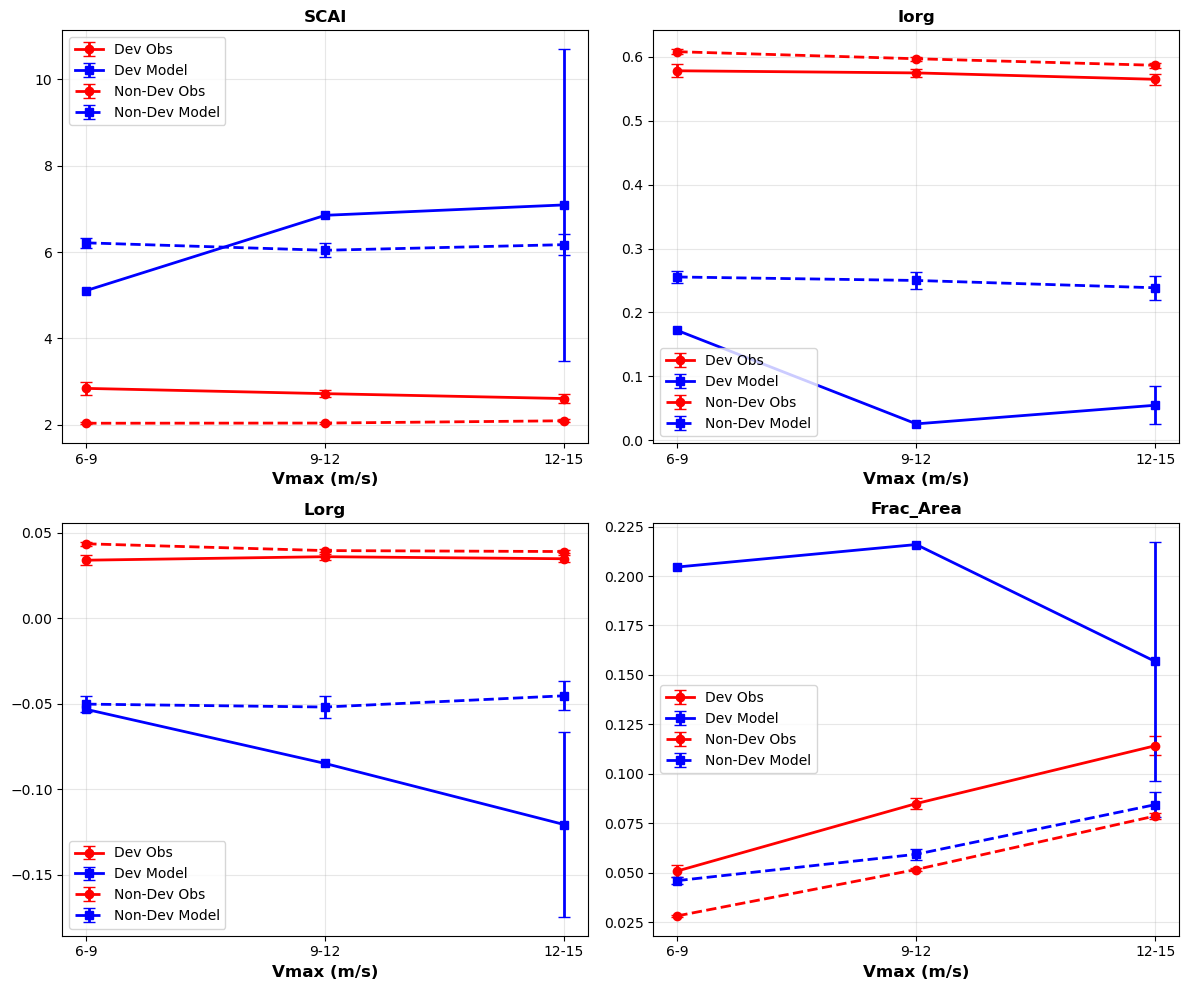

In [12]:
x = ['6-9', '9-12', '12-15']
metrics = ['SCAI', 'Iorg', 'Lorg', 'Frac_Area']

styles = {
    'Dev Obs':       dict(color='red',  linestyle='solid',  marker='o'),
    'Dev Model':     dict(color='blue', linestyle='solid',  marker='s'),
    'Non-Dev Obs':   dict(color='red',  linestyle='dashed', marker='o'),
    'Non-Dev Model': dict(color='blue', linestyle='dashed', marker='s'),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, metric in zip(axes.flat, metrics):
    data = {
        # (values, errors)
        'Dev Obs':       (obs_Data[f'Dev_{metric}'].values,     obs_Data[f'Dev_{metric}_Err'].values),
        'Dev Model':     (Dev_Model[metric],                    Dev_Model[f'{metric}_Err']),
        'Non-Dev Obs':   (obs_Data[f'Non_Dev_{metric}'].values, obs_Data[f'Non_Dev_{metric}_Err'].values),
        'Non-Dev Model': (Non_Dev_Model[metric],                Non_Dev_Model[f'{metric}_Err']),
    }
    for lbl, (y, err) in data.items():
        ax.errorbar(x, y, yerr=err, label=lbl, capsize=4, linewidth=2, **styles[lbl])

    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlabel('Vmax (m/s)', fontsize=12, fontweight='bold')
    ax.grid(True, alpha = 0.3)
    ax.legend()

plt.tight_layout()

In [18]:
print("Everything has Run!!")

Everything has Run!!
